<a href="https://colab.research.google.com/github/kyapster100-eng/cold-chain-edge-ml/blob/main/model_training/train_decision_tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
from datetime import datetime, timedelta

np.random.seed(42)
NUM_SAMPLES = 10000
SAMPLE_INTERVAL_SEC = 60
INITIAL_RSL_HOURS = 120.0

Ea_R = 8000.0
REF_TEMP_K = 277.15
A_FACTOR = np.exp(Ea_R / REF_TEMP_K)

start_time = datetime(2026, 9, 20, 8, 0, 0)
timestamps = [start_time + timedelta(seconds=i * SAMPLE_INTERVAL_SEC) for i in range(NUM_SAMPLES)]

scenarios = np.zeros(NUM_SAMPLES, dtype=int)
scenarios[2500:4500] = 1 # Rough transit (High vibration)
scenarios[4500:6500] = 2 # False alarm door spikes
scenarios[6500:] = 3     # Continuous thermal drift

temp_c = np.zeros(NUM_SAMPLES)
humidity_pct = np.zeros(NUM_SAMPLES)
light_adc = np.zeros(NUM_SAMPLES)
vibration_m_s2 = np.zeros(NUM_SAMPLES)

for i in range(NUM_SAMPLES):
    scen = scenarios[i]
    if scen == 0:
        temp_c[i] = np.random.normal(3.5, 0.5)
        humidity_pct[i] = np.random.normal(88.0, 2.0)
        light_adc[i] = np.random.normal(25.0, 5.0)
        vibration_m_s2[i] = np.random.exponential(0.1)
    elif scen == 1:
        # High transport vibration & humidity drop
        temp_c[i] = np.random.normal(4.2, 0.7)
        humidity_pct[i] = np.random.normal(65.0, 4.0)
        light_adc[i] = np.random.normal(30.0, 8.0)
        vibration_m_s2[i] = np.random.uniform(3.5, 8.0)
    elif scen == 2:
        # Brief light/temp spikes (trips static threshold, but minor thermal impact)
        if np.random.rand() < 0.25:
            temp_c[i] = np.random.uniform(9.0, 13.0)
            light_adc[i] = np.random.uniform(1200.0, 3000.0)
        else:
            temp_c[i] = np.random.normal(4.0, 0.5)
            light_adc[i] = np.random.normal(30.0, 5.0)
        humidity_pct[i] = np.random.normal(82.0, 3.0)
        vibration_m_s2[i] = np.random.exponential(0.2)
    elif scen == 3:
        # True cooling breakdown
        progress = (i - 6500) / (NUM_SAMPLES - 6500)
        drift = 4.0 + (18.0 * (progress ** 1.3))
        temp_c[i] = np.random.normal(drift, 0.8)
        humidity_pct[i] = np.random.normal(70.0 - (20.0 * progress), 4.0)
        light_adc[i] = np.random.normal(45.0, 10.0)
        vibration_m_s2[i] = np.random.exponential(0.2)

# MULTIMODAL GROUND TRUTH CALCULATION
cumulative_loss = np.zeros(NUM_SAMPLES)
rsl_hours = np.zeros(NUM_SAMPLES)
spoilage_status = []

current_loss = 0.0
dt_hr = SAMPLE_INTERVAL_SEC / 3600.0

for i in range(NUM_SAMPLES):
    T_k = temp_c[i] + 273.15

    # 1. Thermal degradation component
    thermal_rate = np.exp(-Ea_R / T_k) * A_FACTOR

    # 2. Vibration fatigue penalty (mechanical damage)
    vib_penalty = 1.0 + (0.45 * (vibration_m_s2[i] ** 1.2) if vibration_m_s2[i] > 2.0 else 0.0)

    # 3. Light breach penalty (photolytic degradation)
    light_penalty = 1.0 + (0.35 if light_adc[i] > 800.0 else 0.0)

    # Combined Multimodal Rate
    effective_rate = thermal_rate * vib_penalty * light_penalty
    step_loss = (100.0 / INITIAL_RSL_HOURS) * effective_rate * dt_hr

    current_loss += step_loss
    current_loss = min(100.0, current_loss)

    cumulative_loss[i] = current_loss
    rsl = max(0.0, (100.0 - current_loss) * 1.2)
    rsl_hours[i] = rsl

    if current_loss < 35.0:
        spoilage_status.append(0) # Safe
    elif current_loss < 75.0:
        spoilage_status.append(1) # Warning
    else:
        spoilage_status.append(2) # Spoiled

df = pd.DataFrame({
    'timestamp': timestamps,
    'temperature_c': np.round(temp_c, 2),
    'humidity_pct': np.round(humidity_pct, 2),
    'light_adc': np.round(light_adc, 1),
    'vibration_m_s2': np.round(vibration_m_s2, 3),
    'quality_loss_pct': np.round(cumulative_loss, 2),
    'rsl_hours': np.round(rsl_hours, 2),
    'spoilage_status': spoilage_status
})

df.to_csv('coldchain_telemetry_dataset.csv', index=False)
print("Dataset updated with authentic multimodal ground truth!")

Dataset updated with authentic multimodal ground truth!



   CORRECTED RESEARCH BENCHMARK RESULTS
Baseline 1 (Threshold) Accuracy:   54.73%
Baseline 2 (Statistical) Accuracy: 77.63%
Proposed (Sensor Fusion ML):       89.87%


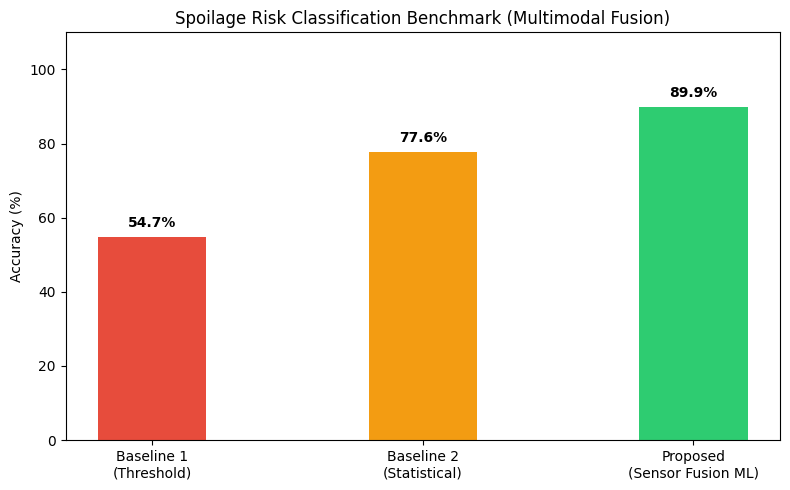

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

df = pd.read_csv('coldchain_telemetry_dataset.csv')

features = ['temperature_c', 'humidity_pct', 'light_adc', 'vibration_m_s2']
X = df[features]
y_status = df['spoilage_status']

# --- BASELINE EVALUATION ---
threshold_preds = []
stat_rsl_preds = []

Ea_R = 8000.0
REF_TEMP_K = 277.15
A_FACTOR = np.exp(Ea_R / REF_TEMP_K)
cum_loss_stat = 0.0

for idx, row in df.iterrows():
    # Baseline 1: Fixed Thresholds (Tripped by brief light/temp spikes)
    if row['temperature_c'] > 8.0 or row['light_adc'] > 800.0:
        threshold_preds.append(2)
    elif row['temperature_c'] > 5.0:
        threshold_preds.append(1)
    else:
        threshold_preds.append(0)

    # Baseline 2: Thermal-Only Arrhenius Statistical Model (Blind to vibration and light)
    T_k = row['temperature_c'] + 273.15
    k_rate = np.exp(-Ea_R / T_k) * A_FACTOR
    cum_loss_stat += (100.0 / 120.0) * k_rate * (1/60.0)

    rsl_stat = max(0.0, (100.0 - cum_loss_stat) * 1.2)
    stat_rsl_preds.append(rsl_stat)

stat_status_preds = []
for rsl in stat_rsl_preds:
    if rsl > 78.0: stat_status_preds.append(0)
    elif rsl > 30.0: stat_status_preds.append(1)
    else: stat_status_preds.append(2)

# --- PROPOSED ML MODEL ---
X_train, X_test, y_train_stat, y_test_stat = train_test_split(X, y_status, test_size=0.3, random_state=42)

test_indices = X_test.index
b1_test_preds = [threshold_preds[i] for i in test_indices]
b2_test_preds = [stat_status_preds[i] for i in test_indices]

# Train Multimodal Random Forest
ml_clf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
ml_clf.fit(X_train, y_train_stat)
ml_test_preds = ml_clf.predict(X_test)

# Accuracies
acc_b1 = accuracy_score(y_test_stat, b1_test_preds) * 100
acc_b2 = accuracy_score(y_test_stat, b2_test_preds) * 100
acc_ml = accuracy_score(y_test_stat, ml_test_preds) * 100

print(f"\n==========================================")
print(f"   CORRECTED RESEARCH BENCHMARK RESULTS")
print(f"==========================================")
print(f"Baseline 1 (Threshold) Accuracy:   {acc_b1:.2f}%")
print(f"Baseline 2 (Statistical) Accuracy: {acc_b2:.2f}%")
print(f"Proposed (Sensor Fusion ML):       {acc_ml:.2f}%")

# Generate Chart
plt.figure(figsize=(8, 5))
bars = plt.bar(['Baseline 1\n(Threshold)', 'Baseline 2\n(Statistical)', 'Proposed\n(Sensor Fusion ML)'],
               [acc_b1, acc_b2, acc_ml], color=['#e74c3c', '#f39c12', '#2ecc71'], width=0.4)
plt.ylabel('Accuracy (%)')
plt.ylim(0, 110)
plt.title('Spoilage Risk Classification Benchmark (Multimodal Fusion)')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 2, f'{yval:.1f}%', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
# Install micromlgen if not present
!pip install micromlgen

from micromlgen import port
from sklearn.tree import DecisionTreeClassifier

# Train a lightweight Decision Tree for low RAM footprint on ESP32
edge_dt = DecisionTreeClassifier(max_depth=6, random_state=42)
edge_dt.fit(X_train, y_train_stat)

# Generate C++ Code
cpp_code = port(edge_dt)

# Save to header file
with open('ColdChainML.h', 'w') as f:
    f.write(cpp_code)

print("Generated 'ColdChainML.h' successfully!")
print("\nFirst 30 lines of C++ Model Code:\n")
print("\n".join(cpp_code.split("\n")[:30]))

  Preparing metadata (setup.py) ... done
  Created wheel for micromlgen: filename=micromlgen-1.1.28-py3-none-any.whl size=32201 sha256=fb0cb1115ba81df2554174c14e5527e2a017884900e1c4658a0cd0284becd888
  Stored in directory: /root/.cache/pip/wheels/f9/b9/ef/39cdd37b184a8a01b0df45454a8367f35d1b34d1b52cd6ea2c
Successfully built micromlgen
Generated 'ColdChainML.h' successfully!

First 30 lines of C++ Model Code:

#pragma once
#include <cstdarg>
namespace Eloquent {
    namespace ML {
        namespace Port {
            class DecisionTree {
                public:
                    /**
                    * Predict class for features vector
                    */
                    int predict(float *x) {
                        if (x[1] <= 84.6349983215332) {
                            if (x[3] <= 3.534500002861023) {
                                if (x[1] <= 83.56499862670898) {
                                    if (x[0] <= 3.0749999284744263) {
                                  

In [ ]:
import time
import numpy as np
import json

# 1. Load your trained Decision Tree model from previous steps
# (edge_dt is already fitted in your notebook)

class ESP32FirmwareSimulator:
    def __init__(self, model):
        self.model = model
        self.cumulative_loss = 0.0
        self.Ea_R = 8000.0
        self.REF_TEMP_K = 277.15
        self.A_FACTOR = np.exp(self.Ea_R / self.REF_TEMP_K)
        self.INITIAL_RSL_HOURS = 120.0

    def update_arrhenius(self, temp_c, dt_hours):
        T_k = temp_c + 273.15
        k_rate = np.exp(-self.Ea_R / T_k) * self.A_FACTOR
        step_loss = (100.0 / self.INITIAL_RSL_HOURS) * k_rate * dt_hours
        self.cumulative_loss = min(100.0, self.cumulative_loss + step_loss)
        return self.cumulative_loss

    def run_cycle(self, temp, humidity, light, vibration, dt_hours=0.005): # ~18 sec step
        # Kinetic Loss Update
        loss = self.update_arrhenius(temp, dt_hours)
        rsl = max(0.0, (100.0 - loss) * 1.2)

        # Edge ML Predict (Features: temp, humidity, light, vibration)
        features = np.array([[temp, humidity, light, vibration]])
        status_code = int(self.model.predict(features)[0])
        labels = {0: "SAFE", 1: "ELEVATED_RISK", 2: "SPOILED"}

        # Construct JSON Payload matching ESP32 telemetry
        payload = {
            "temperature_c": round(temp, 2),
            "humidity_pct": round(humidity, 2),
            "light_adc": round(light, 1),
            "vibration_m_s2": round(vibration, 3),
            "quality_loss_pct": round(loss, 2),
            "rsl_hours": round(rsl, 2),
            "spoilage_status": status_code,
            "spoilage_label": labels[status_code]
        }
        return payload

# Test Simulation Execution
esp32 = ESP32FirmwareSimulator(edge_dt)

test_scenarios = [
    {"desc": "Normal Cold Storage", "temp": 3.8, "hum": 88.0, "light": 25.0, "vib": 0.05},
    {"desc": "Transit Vibration Shock", "temp": 4.1, "hum": 70.0, "light": 30.0, "vib": 4.20},
    {"desc": "Door Open Light Leak", "temp": 11.5, "hum": 60.0, "light": 1800.0, "vib": 0.10},
    {"desc": "Cooling System Failure", "temp": 16.2, "hum": 50.0, "light": 40.0, "vib": 0.15},
]

print("=== ESP32 EDGE FIRMWARE SIMULATION OUTPUT ===")
for sc in test_scenarios:
    telemetry = esp32.run_cycle(sc['temp'], sc['hum'], sc['light'], sc['vib'])
    print(f"\nScenario: {sc['desc']}")
    print(json.dumps(telemetry, indent=2))

=== ESP32 EDGE FIRMWARE SIMULATION OUTPUT ===

Scenario: Normal Cold Storage
{
  "temperature_c": 3.8,
  "humidity_pct": 88.0,
  "light_adc": 25.0,
  "vibration_m_s2": 0.05,
  "quality_loss_pct": 0.0,
  "rsl_hours": 120.0,
  "spoilage_status": 0,
  "spoilage_label": "SAFE"
}

Scenario: Transit Vibration Shock
{
  "temperature_c": 4.1,
  "humidity_pct": 70.0,
  "light_adc": 30.0,
  "vibration_m_s2": 4.2,
  "quality_loss_pct": 0.01,
  "rsl_hours": 119.99,
  "spoilage_status": 2,
  "spoilage_label": "SPOILED"
}

Scenario: Door Open Light Leak
{
  "temperature_c": 11.5,
  "humidity_pct": 60.0,
  "light_adc": 1800.0,
  "vibration_m_s2": 0.1,
  "quality_loss_pct": 0.02,
  "rsl_hours": 119.98,
  "spoilage_status": 2,
  "spoilage_label": "SPOILED"
}

Scenario: Cooling System Failure
{
  "temperature_c": 16.2,
  "humidity_pct": 50.0,
  "light_adc": 40.0,
  "vibration_m_s2": 0.15,
  "quality_loss_pct": 0.03,
  "rsl_hours": 119.96,
  "spoilage_status": 2,
  "spoilage_label": "SPOILED"
}


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
